In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# This script provides the masked data for infilling based downscalling.
# It needs file with original grid (e.g. 0.1 degree) and file with upscaled data (e.g., 1 degree)
# Mask: 0 for points to be infilled, 1 for values to use for infilling.
# Masked_data: HR grid with HR values, except mask==1 where LR data is inserted 

In [1]:
year_min = 1985
year_max = 2025
#year_max = 1987
var = 'relative_humidity'
var_file = '2r'
reg = "_ger"
coarse_res = "_2deg"
add_sfx = "_remapcon_land"

#reg = ""
var_names = {
    "t2m":               "2t",
    #"orography":         "orog",
    #"land_sea_mask":     "lsm",
    "tp":                "tp",
    "relative_humidity": "2r",
    "surface_pressure":  "sp",
    # "wind_speed":        "10si",
    # "wind_direction":    "10wdir",
    "tciwv":             "tciwv",
    "v":    "v",
    "u":    "u",
    "dewpoint": "dewpoint"
    
}
threshold = 0.5 # land is considered with 50% share of the cell


In [2]:
path = '/work/uo1075/u244085/cerra_data/'+var+"/"
path_goratz = "/work/uo1075/u241308/reanalysis/cerra/"+var+"/"
#path = path_goratz

# Single input

In [ ]:
for var, var_file in var_names.items():
    for year in range(year_min,year_max+1):
        # ========= load high resolution data ==============
        path = '/work/uo1075/u244085/cerra_data/'+var+"/"
        path_goratz = "/work/uo1075/u241308/reanalysis/cerra/"+var+"/"
        #path = path_goratz
        #path = '/work/uo1075/u244085/cerra_data/t2m/'
        file = 'cerra_sub_'+var+"_"+str(year)+ add_sfx +reg+'.nc'
        original_data = xr.open_dataset(path+file)[var_file]
        print(original_data)
        #original_data = original_data.rename({'lon':'lon','lat':'lat'})
        if original_data.time.size > 2920:
            print("Days corrupt", file, original_data.time.size)
        #original_data = original_data.rename({'valid_time': 'time'})
        #original_data = remove_leap_days(original_data) #leap years to 365
    
        # ========= load low resolution data ==============
        #path = '/work/uo1075/u244085/trees_in_the_city/data/era5_land/'+var+'/lowres/'
        #path_goratz = "/work/uo1075/u241308/data_python_PostDoc/BB_challenge/data/era5_land/"+var+'/lowres/'
        #path = path_goratz
        file = 'cerra_sub_'+var+'_'+str(year) + add_sfx+reg+coarse_res+'.nc'
        
        coarse_data = xr.open_dataset(path+file)[var_file]
        #coarse_data = coarse_data.rename({'lon':'lon','lat':'lat'})
        #coarse_data = coarse_data.rename({'valid_time': 'time'})
        #coarse_data = remove_leap_days(coarse_data) #leap years to 365
        #print("days in file",coarse_data.time.size)
        
        #new lons
        coarse_data['lon'] = np.where(coarse_data.lon > 180,coarse_data.lon-360,coarse_data.lon)
        ind_sort = np.argsort(coarse_data.lon)
        coarse_data = coarse_data.isel(lon=np.argsort(coarse_data.lon.values))
        
        # ========= create a mask with high resolution data ==============
        # High-res coordinates
        lat_hr = original_data.lat.values
        lon_hr = original_data.lon.values
        dlat = abs(lat_hr[1] - lat_hr[0])
        dlon = abs(lon_hr[1] - lon_hr[0])
        lat0 = lat_hr[0]   # e.g. 72.0
        lon0 = lon_hr[0]   # e.g. -15.0
            # OLD 
        # Compute high-res indices of coarse grid centers
        #ilat = np.round((lat0 - coarse_data.lat.values) / dlat).astype(int) #this was for descending latitudes
        # ilat = np.round((coarse_data.latitude.values - lat0) / dlat).astype(int) #for ascending latitudes, inverted with CDO
        # ilon = np.round((coarse_data.longitude.values - lon0) / dlon).astype(int)
        
        # # Valid indices
        # lat_valid = (ilat >= 0) & (ilat < lat_hr.size)
        # lon_valid = (ilon >= 0) & (ilon < lon_hr.size)
        # NEW
        def nearest_idx(grid_vals, target_vals):
            # index into grid_vals for each target_val
            return np.abs(np.asarray(grid_vals, dtype='f8')[:, None]
                        - np.asarray(target_vals, dtype='f8')[None, :]).argmin(axis=0)
    
        ilat = nearest_idx(lat_hr, coarse_data.lat.values)
        ilon = nearest_idx(lon_hr, coarse_data.lon.values)
        lat_valid = np.abs(lat_hr[ilat] - coarse_data.lat.values) < dlat/2 + 1e-6
        lon_valid = np.abs(lon_hr[ilon] - coarse_data.lon.values) < dlon/2 + 1e-6
     
        # # Reduce coarse data accordingly
        coarse_valid = coarse_data.isel(
            lat=np.where(lat_valid)[0],
            lon=np.where(lon_valid)[0],
        )
        
        #create masked file
        masked_data = original_data.copy()
        masked_data[:] = 0
        masked_data = masked_data.where(~np.isnan(original_data), other=np.nan)  # keep ocean NaNs
        # Set the coarse values at the centers
        masked_data.values[:,ilat[:, None],ilon[None, :]] = coarse_valid.values
    
        # # ======== Create a mask file and save - WITH TIME DIMENSION ================
        # # 0 for all gridpoints (including ocean/NaN and gridpoints to infill)
        # # 1 only where coarse values are
        mask = xr.where((masked_data != 0) & (~np.isnan(masked_data)), 1, 0)
        steady_mask = (~np.isnan(original_data)).astype(int)
        mask = mask * steady_mask
        
        path = '/work/uo1075/u244085/cerra_data/mask/'
        file = 'cerra_sub_'+var+'_'+reg+str(year)+'_mask.nc'
        mask.to_netcdf(path+file)
    
        # # ======== Create a steady mask file and save - WITH TIME DIMENSION ================
        # 0 for gridpoints to be ignored by the training (e.g. ocean)
        # 1 for gridpoints contributing to the training
        file = 'cerra_dm_land_sea_mask_'+'2005'+reg.nc
        path = '/work/uo1075/u244085/cerra_data/land_sea_mask/'
        ds = xr.open_dataset(path+file)
        ds = ds.rename({"lsm": var_file})
        lsm_data = ds[var_file]
        lsm_binary = lsm_data.where(lsm_data >= threshold, 0) 
        steady_mask = lsm_binary.where(lsm_binary < threshold, 1) 
        # steady_mask = (~np.isnan(original_data)).astype(int)
        # steady_mask = steady_mask.isel(time=0)
        path = '/work/uo1075/u244085/cerra_data/mask/'
        file = 'cerra_sub_'+var+str(year)+'_'+reg+'_steady_mask.nc'
        steady_mask.to_netcdf(path+file)
    
        # # ============= use HR values where not used for infilling (downscalling) ==============
        masked_data = xr.where(masked_data==0,original_data,masked_data)
    
        # # ============= set regrided ocean nans to zeros ==============
        masked_data_to_test = xr.where(np.isnan(masked_data),0,masked_data) #includes all gridpoints onshore due to remapcon
        masked_data = xr.where(np.isnan(original_data),0,masked_data) #exclude all gridpoints onshore
        
        # # ================ save low res data on high res grid + data =============
        path = '/work/uo1075/u244085/cerra_data/'+ var + "/"
        file = 'cerra_sub_'+var+'_'+reg+str(year)+'_lowres_values_filled_highres_grid'+coarse_res+'.nc'
        masked_data.to_netcdf(path+file)
    
        # # ================ high res data in high res grid, with zeros as in masked_data =============
        highres_masked = xr.where(masked_data != 0, original_data, masked_data)
        # path = '/work/uo1075/u244085/trees_in_the_city/data/era5_land/'+var+'/lowres_in_highres_grid/'
        # file = 'era5_land_'+var+'_daily_'+str(year)+'_europe_highres_values_in_highres_grid.nc'    
        # #highres_masked.to_netcdf(path+file)
        
        print('Var '+var+' Year '+str(year)+' done')

<xarray.DataArray '2t' (time: 2920, lat: 201, lon: 241)> Size: 566MB
[141447720 values with dtype=float32]
Coordinates:
  * time     (time) object 23kB 1985-01-01 00:00:00 ... 1985-12-31 21:00:00
  * lon      (lon) float64 2kB 4.0 4.05 4.1 4.15 4.2 ... 15.85 15.9 15.95 16.0
  * lat      (lat) float64 2kB 46.0 46.05 46.1 46.15 ... 55.85 55.9 55.95 56.0
Attributes:
    standard_name:  air_temperature
    long_name:      2 metre temperature
    units:          K
    param:          0.0.0
    cell_methods:   height: mean
Var t2m Year 1985 done
<xarray.DataArray '2t' (time: 2920, height: 1, lat: 201, lon: 241)> Size: 566MB
[141447720 values with dtype=float32]
Coordinates:
  * time     (time) object 23kB 1986-01-01 00:00:00 ... 1986-12-31 21:00:00
  * lon      (lon) float64 2kB 4.0 4.05 4.1 4.15 4.2 ... 15.85 15.9 15.95 16.0
  * lat      (lat) float64 2kB 46.0 46.05 46.1 46.15 ... 55.85 55.9 55.95 56.0
  * height   (height) float64 8B 2.0
Attributes:
    standard_name:  air_temperature
    

ValueError: shape mismatch: value array of shape (2920,1,6,6) could not be broadcast to indexing result of shape (2920,6,6,241)

# Filled

In [7]:
year = 2005
#year_max = 1987
var = 'orography'
var_file = 'orog'
reg = "ger_"
file = 'cerra_dm_land_sea_mask_'+reg+'2005'+'.nc'
path = '/work/uo1075/u244085/cerra_data/land_sea_mask/'
ds = xr.open_dataset(path+file)
ds = ds.rename({"lsm": var_file})
lsm_data = ds[var_file]

lsm_binary = lsm_data.where(lsm_data >= threshold, 0) 
steady_mask = lsm_binary.where(lsm_binary < threshold, 1) 
# steady_mask = (~np.isnan(original_data)).astype(int)
# steady_mask = steady_mask.isel(time=0)
mask = (lsm_data >= 0).astype(int)
path = '/work/uo1075/u244085/cerra_data/mask/'
file = 'cerra_dm_'+var+'_'+str(year)+"_"+reg+'mask.nc'
mask.to_netcdf(path+file)
path = '/work/uo1075/u244085/cerra_data/mask/'
file = 'cerra_dm_'+var+'_'+str(year)+"_"+reg+'steady_mask.nc'
steady_mask.to_netcdf(path+file)

In [10]:
import numpy as np
import xarray as xr


# int8 + compression for the 0/1 mask files
mask_enc = {'dtype': 'int8', '_FillValue': None, 'zlib': True, 'complevel': 4}


def nearest_idx(grid_vals, target_vals):
    """index into grid_vals nearest to each target value"""
    return np.abs(np.asarray(grid_vals, dtype='f8')[:, None]
                  - np.asarray(target_vals, dtype='f8')[None, :]).argmin(axis=0)


def to_time(da, template):
    """Tile a time-independent (lat, lon) field onto template's time axis,
    so the result carries exactly the same time dimension/coords as template."""
    da = da.squeeze()
    if 'time' in da.dims:                 # static file may still carry a dummy time
        da = da.isel(time=0)
    da = xr.concat([da] * template.sizes['time'], dim='time')
    return da.assign_coords(time=template.time)


for var, var_file in var_names.items():
    for year in range(year_min, year_max + 1):

        # ========= load high resolution data ==============
        path = '/work/uo1075/u244085/cerra_data/' + var + "/"
        file = 'cerra_dm_' + var + '_' + str(year) + add_sfx + reg + '.nc'
        original_data = xr.open_dataset(path + file)[var_file]
        if original_data.time.size > 365:
            print("Days corrupt", file, original_data.time.size)

        # ========= load low resolution data ==============
        file = 'cerra_dm_' + var + '_' + str(year) + add_sfx + reg + coarse_res + '.nc'
        coarse_data = xr.open_dataset(path + file)[var_file]

        # new lons
        coarse_data['lon'] = np.where(coarse_data.lon > 180,
                                      coarse_data.lon - 360, coarse_data.lon)
        coarse_data = coarse_data.isel(lon=np.argsort(coarse_data.lon.values))

        assert coarse_data.time.size == original_data.time.size, \
            f"time mismatch {var} {year}"

        # ========= block fill: all 5km cells in a 2deg cell get the coarse value ==============
        lat_hr = original_data.lat.values
        lon_hr = original_data.lon.values

        dlat_c = abs(coarse_data.lat.values[1] - coarse_data.lat.values[0])
        dlon_c = abs(coarse_data.lon.values[1] - coarse_data.lon.values[0])

        ic_lat = nearest_idx(coarse_data.lat.values, lat_hr)
        ic_lon = nearest_idx(coarse_data.lon.values, lon_hr)

        inside = ((np.abs(coarse_data.lat.values[ic_lat] - lat_hr) <= dlat_c / 2 + 1e-6)[:, None]
                  & (np.abs(coarse_data.lon.values[ic_lon] - lon_hr) <= dlon_c / 2 + 1e-6)[None, :])

        blocky = coarse_data.values[:, ic_lat[:, None], ic_lon[None, :]]

        masked_data = original_data.copy()
        masked_data[:] = np.where(inside[None, :, :], blocky, 0)
        masked_data = masked_data.where(~np.isnan(original_data), other=np.nan)

        # ======== mask file: 1 everywhere, same time dim as the data ==============
        # ones_like copies dims/coords (incl. time) of original_data, all values = 1
        mask = xr.ones_like(original_data, dtype='int8').rename(var_file)

        assert mask.sizes['time'] == original_data.sizes['time'], \
            f"filled mask time mismatch {var} {year}"

        path = '/work/uo1075/u244085/cerra_data/mask/'
        file = 'cerra_dm_' + var + "_" + str(year) + reg + '_filled_mask.nc'
        mask.to_netcdf(path + file, encoding={var_file: mask_enc})

        # ======== steady mask file (land-sea), tiled onto the data's time axis ==============
        file = 'cerra_dm_land_sea_mask' + reg + '_2005.nc'
        path_lsm = '/work/uo1075/u244085/cerra_data/land_sea_mask/'
        ds = xr.open_dataset(path_lsm + file)
        lsm_data = ds['lsm']

        # FIX: same result as the old where-chains, but in one step,
        # and tiled over time so it matches the data's time dimension
        steady_mask = (lsm_data >= 0.5).astype('int8')
        steady_mask = to_time(steady_mask, original_data).rename(var_file)

        assert steady_mask.sizes['time'] == original_data.sizes['time'], \
            f"steady mask time mismatch {var} {year}"

        path = '/work/uo1075/u244085/cerra_data/mask/'
        file = 'cerra_dm_' + var + "_" + str(year) + reg + '_steady_mask.nc'
        steady_mask.to_netcdf(path + file, encoding={var_file: mask_enc})

        # ============= ocean nans to zeros, save blocky lowres-on-highres ==============
        masked_data = xr.where(np.isnan(masked_data), 0, masked_data)

        path = '/work/uo1075/u244085/cerra_data/' + var + "/"
        file = 'cerra_dm_' + var + '_' + str(year) + reg \
               + '_lowres_values_filled_highres_grid' + coarse_res + '.nc'
        masked_data.to_netcdf(path + file)

        print('Var ' + var + ' Year ' + str(year) + ' done')

Var t2m Year 1985 done
Var t2m Year 1986 done
Var t2m Year 1987 done
Var t2m Year 1988 done
Var t2m Year 1989 done
Var t2m Year 1990 done
Var t2m Year 1991 done
Var t2m Year 1992 done
Var t2m Year 1993 done
Var t2m Year 1994 done
Var t2m Year 1995 done
Var t2m Year 1996 done
Var t2m Year 1997 done
Var t2m Year 1998 done
Var t2m Year 1999 done
Var t2m Year 2000 done
Var t2m Year 2001 done
Var t2m Year 2002 done
Var t2m Year 2003 done
Var t2m Year 2004 done
Var t2m Year 2005 done
Var t2m Year 2006 done
Var t2m Year 2007 done
Var t2m Year 2008 done
Var t2m Year 2009 done
Var t2m Year 2010 done
Var t2m Year 2011 done
Var t2m Year 2012 done
Var t2m Year 2013 done
Var t2m Year 2014 done
Var t2m Year 2015 done
Var t2m Year 2016 done
Var t2m Year 2017 done
Var t2m Year 2018 done
Var t2m Year 2019 done
Var t2m Year 2020 done
Var t2m Year 2021 done
Var t2m Year 2022 done
Var t2m Year 2023 done
Var t2m Year 2024 done
Var t2m Year 2025 done
Var tp Year 1985 done
Var tp Year 1986 done
Var tp Year 1

In [12]:
year = 2005
#year_max = 1987
var = 'orography'
var_file = 'orog'
reg = "ger_"
file = 'cerra_dm_land_sea_mask_'+reg+'2005.nc'
path = '/work/uo1075/u244085/cerra_data/land_sea_mask/'
ds = xr.open_dataset(path+file)
ds = ds.rename({"lsm": var_file})
lsm_data = ds[var_file]

lsm_binary = lsm_data.where(lsm_data >= threshold, 0) 
steady_mask = lsm_binary.where(lsm_binary < threshold, 1) 
# steady_mask = (~np.isnan(original_data)).astype(int)
# steady_mask = steady_mask.isel(time=0)
mask = (lsm_data >= 0).astype(int)
path = '/work/uo1075/u244085/cerra_data/mask/'
file = 'cerra_dm_'+var+'_'+str(year)+"_"+reg+'filled_mask.nc'
mask.to_netcdf(path+file)
path = '/work/uo1075/u244085/cerra_data/mask/'
file = 'cerra_dm_'+var+'_'+str(year)+"_"+reg+'filled_steady_mask.nc'
steady_mask.to_netcdf(path+file)

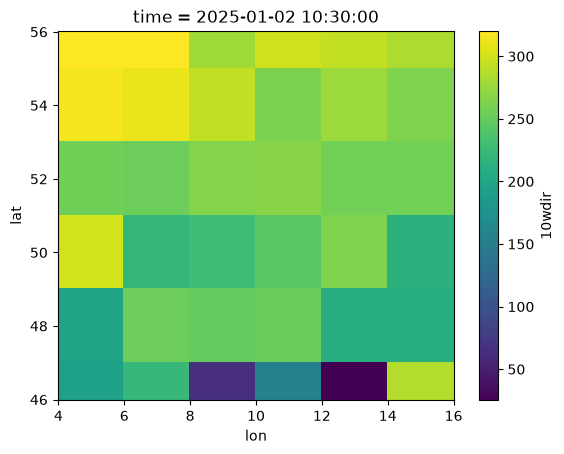

In [20]:
masked_data.isel(time=1).plot()

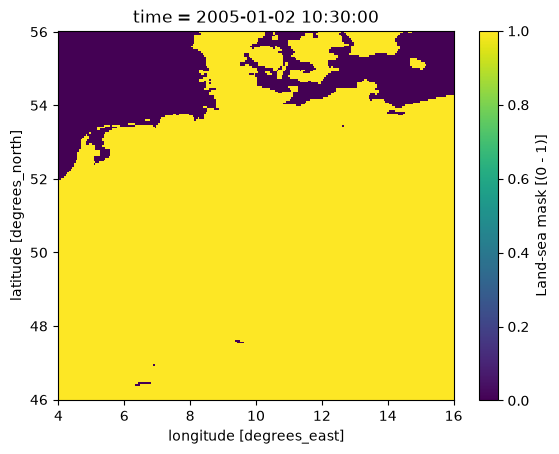

In [9]:
steady_mask.isel(time=1).plot()

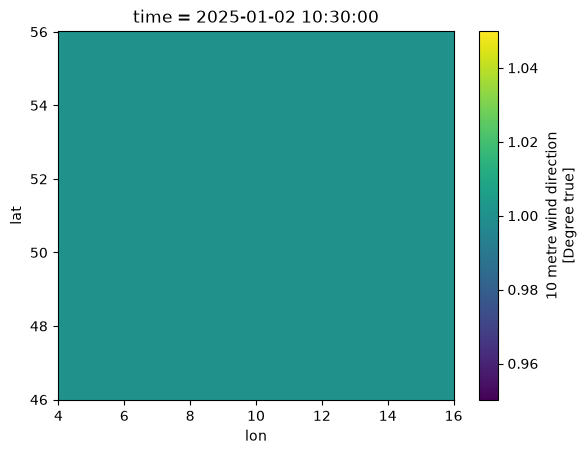

In [21]:
mask.isel(time=1).plot()

# Plotting of maps

n coarse pts: 52195  n HR pts: 17628770


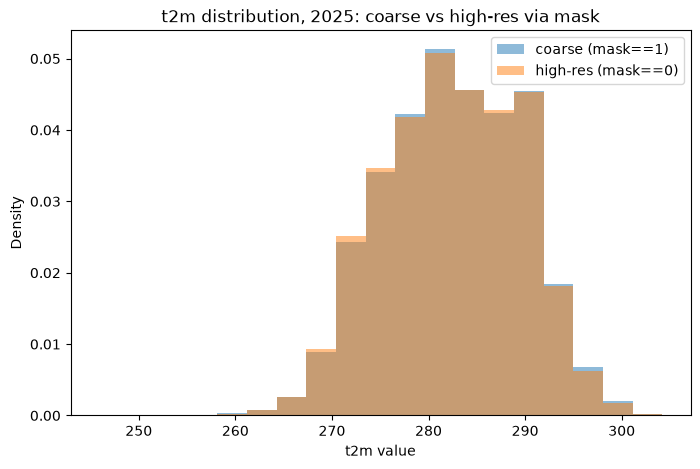

mean: coarse 282.59033  HR 282.50253
std : coarse 7.092401  HR 7.07103
q0.01: coarse 266.93  HR 267.07
q0.05: coarse 271.03  HR 270.99
q0.95: coarse 293.41  HR 293.21
q0.99: coarse 297.38  HR 297.12


In [27]:
# ===== distributions via the mask =====
# mask: 1 = coarse value placed there, 0 = HR/ocean
# steady_mask: 1 = land, 0 = ocean

# coarse (low-res) values: only at mask==1 points
low_vals = masked_data.where(mask == 1).values.ravel()
low_vals = low_vals[~np.isnan(low_vals)]

# high-res values: mask==0 points on land (ocean is NaN → dropped automatically)
high_vals = original_data.where((mask == 0)).values.ravel()
high_vals = high_vals[~np.isnan(high_vals)]

print("n coarse pts:", low_vals.size, " n HR pts:", high_vals.size)

bins = np.linspace(min(low_vals.min(), high_vals.min()),
                   max(low_vals.max(), high_vals.max()), 20)

plt.figure(figsize=(8, 5))
plt.hist(low_vals,  bins=bins, alpha=0.5, density=True, label='coarse (mask==1)')
plt.hist(high_vals, bins=bins, alpha=0.5, density=True, label='high-res (mask==0)')
plt.xlabel(f"{var} value")
plt.ylabel("Density")
plt.title(f"{var} distribution, {year}: coarse vs high-res via mask")
plt.legend()
plt.show()

print("mean: coarse", low_vals.mean(), " HR", high_vals.mean())
print("std : coarse", low_vals.std(),  " HR", high_vals.std())
for q in [0.01, 0.05, 0.95, 0.99]:
    print(f"q{q:0.2f}: coarse {np.quantile(low_vals, q):.2f}  HR {np.quantile(high_vals, q):.2f}")

In [ ]:
row = 2
column = 2

fig = plt.figure(figsize=(25,20))#(22,15))
plt.rcParams.update({'font.size': 12})

if original_data is None:
    original_data = xr.open_dataset()


ax1 = fig.add_subplot(row,column,1)
plt.pcolormesh(original_data.lon,original_data.lat, mask[0] * steady_mask[0])
plt.title("Mask*Steady mask")
plt.colorbar()
ax2 = fig.add_subplot(row,column,2)

mask_inv = (1- mask[0] * steady_mask[0])  * steady_mask[0]
plt.pcolormesh(mask.lon,mask.lat, mask_inv)
plt.title("Inverted mask")
plt.colorbar()

ax3 = fig.add_subplot(row,column,3)
plt.pcolormesh(mask.lon,mask.lat,mask[0])
plt.title("Mask")
plt.colorbar()

ax4 = fig.add_subplot(row,column,4)
plt.pcolormesh(steady_mask.lon,steady_mask.lat,steady_mask[0])
plt.title("Steady Mask")
plt.colorbar()

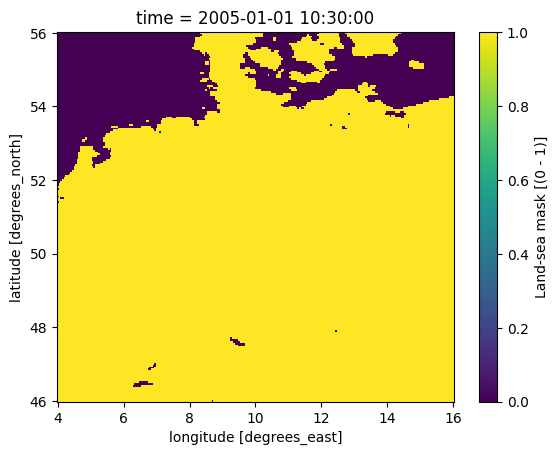

In [3]:
reg = "ger_"
var = "land_sea_mask"
file = 'cerra_dm_land_sea_mask_'+reg+'2005.nc'
path = '/work/uo1075/u244085/cerra_data/land_sea_mask/'
lsm_data = xr.open_dataset(path+file)["lsm"]
threshold = 0.5
lsm_binary = lsm_data.where(lsm_data >= threshold, 0) 
lsm_binary = lsm_binary.where(lsm_binary < threshold, 1) 
lsm_binary.isel(time=0).plot()

# Sanity check

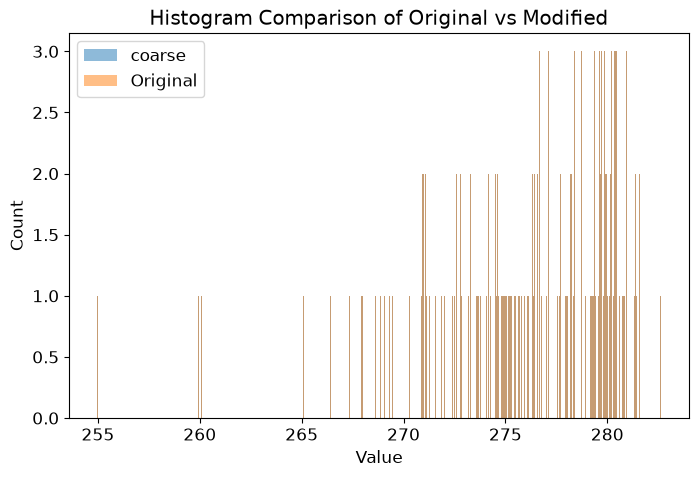

In [23]:
#both histograms should be different: data to be used for infilling in masked_data should be low resolution,
#while the high resolution file should have HR values
low_res_mask_joker = xr.where(mask[0]==1,masked_data[0],np.nan)
low_res_mask_joker = xr.where(low_res_mask_joker==0,np.nan,low_res_mask_joker)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

high_res_mask_joker = xr.where(mask[0]==1,highres_masked[0],np.nan)
high_res_mask_joker = xr.where(high_res_mask_joker==0,np.nan,high_res_mask_joker)
high_res_mask_joker = high_res_mask_joker.values.flatten()
high_res_mask_joker = high_res_mask_joker[~np.isnan(high_res_mask_joker)]

bins = np.linspace(
    min(low_res_mask_joker.min(), high_res_mask_joker.min()),
    max(low_res_mask_joker.max(), high_res_mask_joker.max()),
    500
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='coarse')
plt.hist(high_res_mask_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

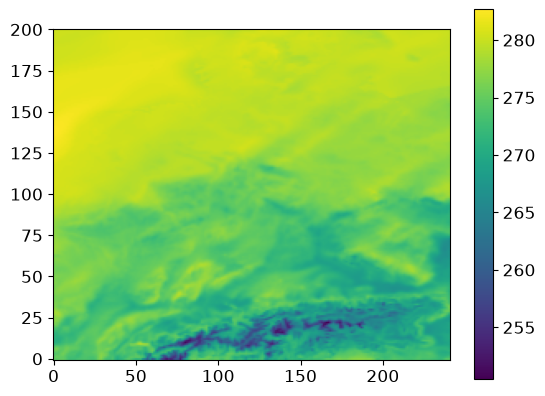

0.0 0.0
4.5607 4.5607


In [19]:
# 1. Look at a single time step — you should see blocky 1° patches
plt.imshow(masked_data.isel(time=0), origin='lower'); plt.colorbar(); plt.show()

# 2. Pointwise difference and spread
diff = highres_masked.where(mask==1) - masked_data.where(mask==1)
print(diff.mean().item(), diff.std().item())
print(low_res_mask_joker.std(), high_res_mask_joker.std())  # coarse should be slightly lower

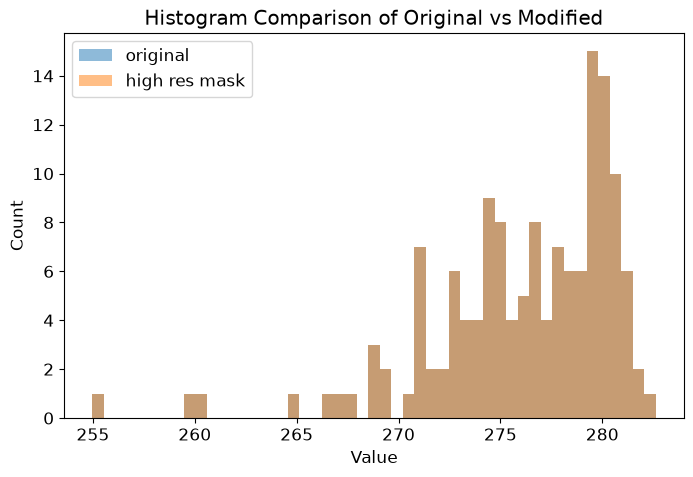

In [10]:
#both histograms should be identical, both HR values
high_res_joker = xr.where(mask[0]==1,original_data[0],np.nan)
high_res_joker = high_res_joker.values.flatten()
high_res_joker = high_res_joker[~np.isnan(high_res_joker)]

high_res_mask_joker = xr.where(mask[0]==1,highres_masked[0],np.nan)
high_res_mask_joker = high_res_mask_joker.values.flatten()
high_res_mask_joker = high_res_mask_joker[~np.isnan(high_res_mask_joker)]

bins = np.linspace(
    min(high_res_joker.min(), high_res_joker.min()),
    max(high_res_joker.max(), high_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(high_res_joker, bins=bins, alpha=0.5, label='original')
plt.hist(high_res_mask_joker, bins=bins, alpha=0.5, label='high res mask')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

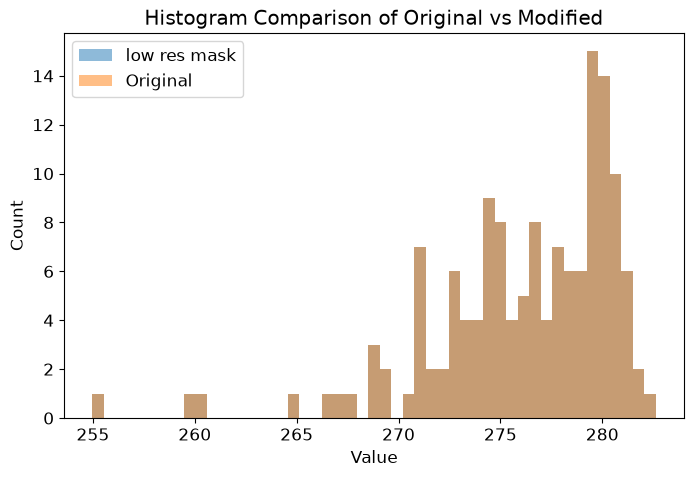

In [11]:
#both histograms should be identical
low_res_joker = coarse_data[0].values.flatten()
low_res_joker = low_res_joker[~np.isnan(low_res_joker)]

low_res_mask_joker = xr.where(mask[0]==1,masked_data_to_test[0],np.nan)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

bins = np.linspace(
    min(low_res_joker.min(), low_res_joker.min()),
    max(low_res_joker.max(), low_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='low res mask')
plt.hist(low_res_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

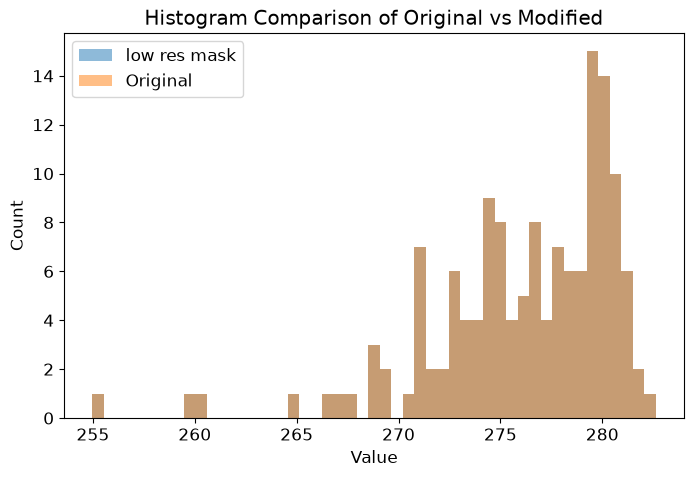

In [12]:
#both histograms should be different, with original above mask data, because we excluded onshore gridpoints, artifact of remapcon upscaling 
low_res_joker = coarse_data[0].values.flatten()
low_res_joker = low_res_joker[~np.isnan(low_res_joker)]

low_res_mask_joker = xr.where(mask[0]==1,masked_data[0],np.nan)
low_res_mask_joker = low_res_mask_joker.values.flatten()
low_res_mask_joker = low_res_mask_joker[~np.isnan(low_res_mask_joker)]

bins = np.linspace(
    min(low_res_joker.min(), low_res_joker.min()),
    max(low_res_joker.max(), low_res_joker.max()),
    50
)

# Plot histogram
plt.figure(figsize=(8,5))
plt.hist(low_res_mask_joker, bins=bins, alpha=0.5, label='low res mask')
plt.hist(low_res_joker, bins=bins, alpha=0.5, label='Original')
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Histogram Comparison of Original vs Modified")
plt.legend()
plt.show()

Text(0.5, 1.0, 'Masked Data (non-NaN points)')

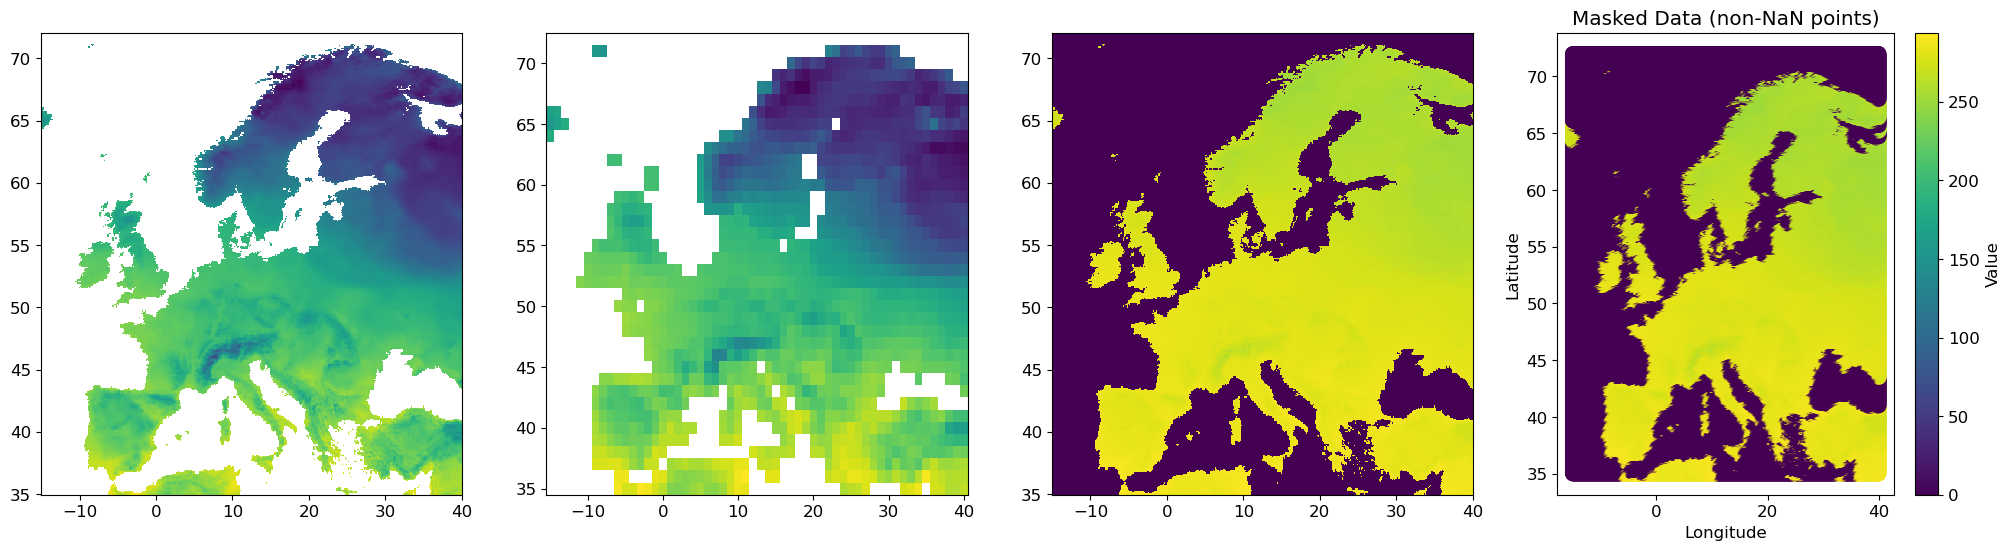

In [10]:
#Plot
row = 1
column = 4

fig = plt.figure(figsize=(25,6))#(22,15))
plt.rcParams.update({'font.size': 12})

ax1 = fig.add_subplot(row,column,1)
plt.pcolormesh(original_data.lon,original_data.lat,original_data[0])

ax2 = fig.add_subplot(row,column,2)
plt.pcolormesh(coarse_data.lon,coarse_data.lat,coarse_data[0])

ax3 = fig.add_subplot(row,column,3)
plt.pcolormesh(masked_data.lon,masked_data.lat,masked_data[0])

ax4 = fig.add_subplot(row,column,4)
# Get coordinates and values of non-NaN points
lat = masked_data.lat.values
lon = masked_data.lon.values
values = masked_data.values  # shape: (time, lat, lon)

# For simplicity, pick one time slice, e.g., first one
data_slice = values[0]  # shape: (lat, lon)
lat_grid, lon_grid = np.meshgrid(lat, lon, indexing='ij')

# Mask NaNs
mask_joker = ~np.isnan(data_slice)
plt.scatter(lon_grid[mask_joker], lat_grid[mask_joker], c=data_slice[mask_joker], s=100, cmap='viridis')
plt.colorbar(label='Value')
plt.xlabel('lon')
plt.ylabel('lat')
plt.title('Masked Data (non-NaN points)')

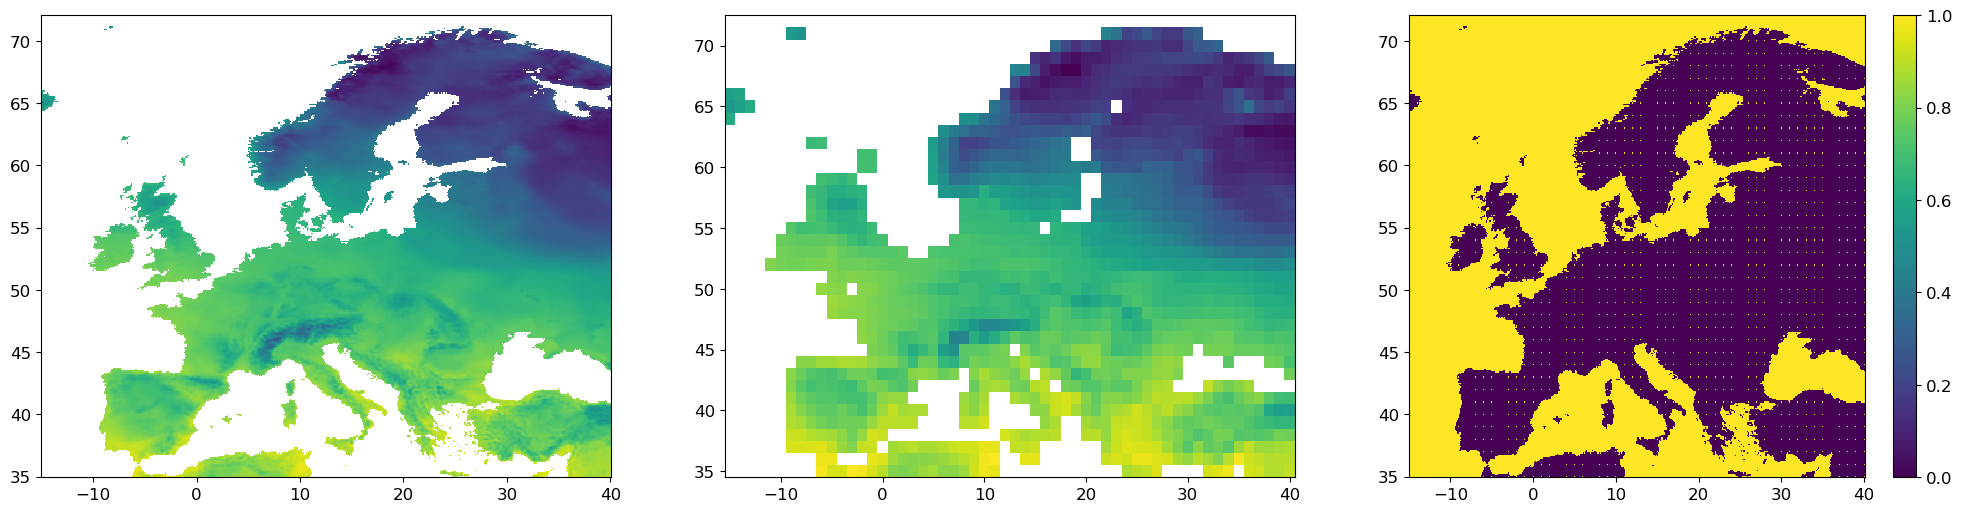

In [ ]:
row = 2
column = 2

fig = plt.figure(figsize=(25,6))#(22,15))
plt.rcParams.update({'font.size': 12})

ax1 = fig.add_subplot(row,column,1)
plt.pcolormesh(original_data.lon,original_data.lat,original_data[0])

ax2 = fig.add_subplot(row,column,2)
plt.pcolormesh(coarse_data.lon,coarse_data.lat,coarse_data[0])

ax3 = fig.add_subplot(row,column,3)
plt.pcolormesh(original_data.lon,original_data.lat,mask[0])
plt.colorbar()

ax4 = fig.add_subplot(row,column,4)
plt.pcolormesh(original_data.lon,original_data.lat,steady_mask[0])
plt.colorbar()

In [12]:
# none of the files should have nans

# Idea 1: 
# input: high resolution data, mask file => training
# reconstruct: low resolution data
# downside: might loose spatial variability as the training only sees high resolution, but reconstruct low resolution. Link between low and high resolution.

# Idea 2:
# INput: low resolution data, mask file => training
# downside: the exact point (1/10) will be missing. 
